In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.ndimage import gaussian_filter
from scipy.io import loadmat
from pathlib import Path
from matplotlib.patches import Rectangle
import re
import os


if os.getcwd().endswith('scripts'):
    os.chdir('..')
os.getcwd()

'/Users/arthur/git/Master amu/DA3_VSDI_S1_G1_2026'

In [2]:
## load the condition
## condition is the order of the finger stimulations

condition_load = np.load('data/New_list_conditions.npy')
condition = []

for i in condition_load[0::2]:
    cond = re.split('_', str(i))[0]
    condition.append(cond[-1])

condition = np.array(condition)

### Extract data

In [3]:
# parameters
sig = 1 ## for the gaussian filter

In [4]:
## extract data from trials

data_dir = Path('/Users/arthur/git/Master amu/DA3_VSDI_S1_G1_2026/data') ## put your own path
Cortex = np.load('data/Image_Cortex.npy')  
x = np.arange(1, 31, 1)

delta_f = []

for trial_num in x:
    stim = np.load(data_dir / f'Trial_{trial_num}_Stim.npy')
    control = np.load(data_dir / f'Trial_{trial_num}_Control.npy')

    df = (stim - control)/control
    delta_f.append(df)

delta_f = np.array(delta_f)

df_filtered = gaussian_filter(delta_f.copy(), sigma=(0, sig, sig, 0)) 
# df_test = gaussian_filter(delta_f.copy(), sigma=(0, sig, sig, sig))

In [5]:
cond1_index = np.where(condition == '1')[0]
cond2_index = np.where(condition == '2')[0]
cond3_index = np.where(condition == '3')[0]

In [6]:
## filter before or after taking mean?

cond1_ave = np.mean(df_filtered[cond1_index], axis=0)
cond2_ave = np.mean(df_filtered[cond2_index], axis=0)
cond3_ave = np.mean(df_filtered[cond3_index], axis=0)

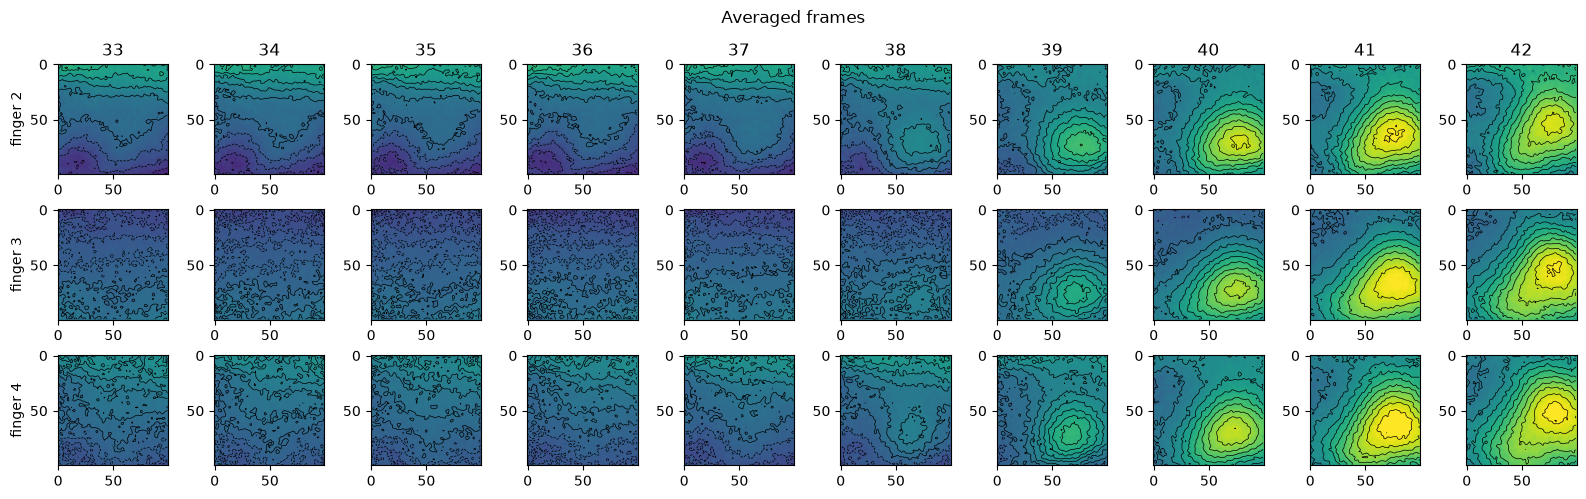

In [40]:
fig, ax = plt.subplots(3, 10, figsize=(16,5))

vmin = np.min(cond1_ave)
vmax=np.max(cond1_ave)

level=10

for i in range(10):
    ax[0][i].imshow(cond1_ave[:,:,33+i], vmin=vmin, vmax=vmax)
    ax[1][i].imshow(cond2_ave[:,:,33+i], vmin=vmin, vmax=vmax)
    ax[2][i].imshow(cond3_ave[:,:,33+i], vmin=vmin, vmax=vmax)

    ax[0][i].contour(cond1_ave[:,:,33+i], levels=level, linewidths=0.5, colors='k')
    ax[1][i].contour(cond2_ave[:,:,33+i], levels=level, linewidths=0.5, colors='k')
    ax[2][i].contour(cond3_ave[:,:,33+i], levels=level, linewidths=0.5, colors='k')

    ax[0][i].set_title(33+i)

ax[0][0].set_ylabel('finger 2')
ax[1][0].set_ylabel('finger 3')
ax[2][0].set_ylabel('finger 4')

fig.suptitle('Averaged frames')
plt.tight_layout()

In [8]:
# Is it better to have one maximum for all conditions or one maximum per condition

cond1_max = cond1_ave[:,:,33:40].max()
cond2_max = cond2_ave[:,:,33:40].max()
cond3_max = cond3_ave[:,:,33:40].max()

In [77]:
thresh = 0.85

cond1_thresh = np.where(cond1_ave > cond1_max * thresh, cond1_ave, 0)
cond2_thresh = np.where(cond2_ave > cond2_max * thresh, cond1_ave, 0)
cond3_thresh = np.where(cond3_ave > cond3_max * thresh, cond1_ave, 0)

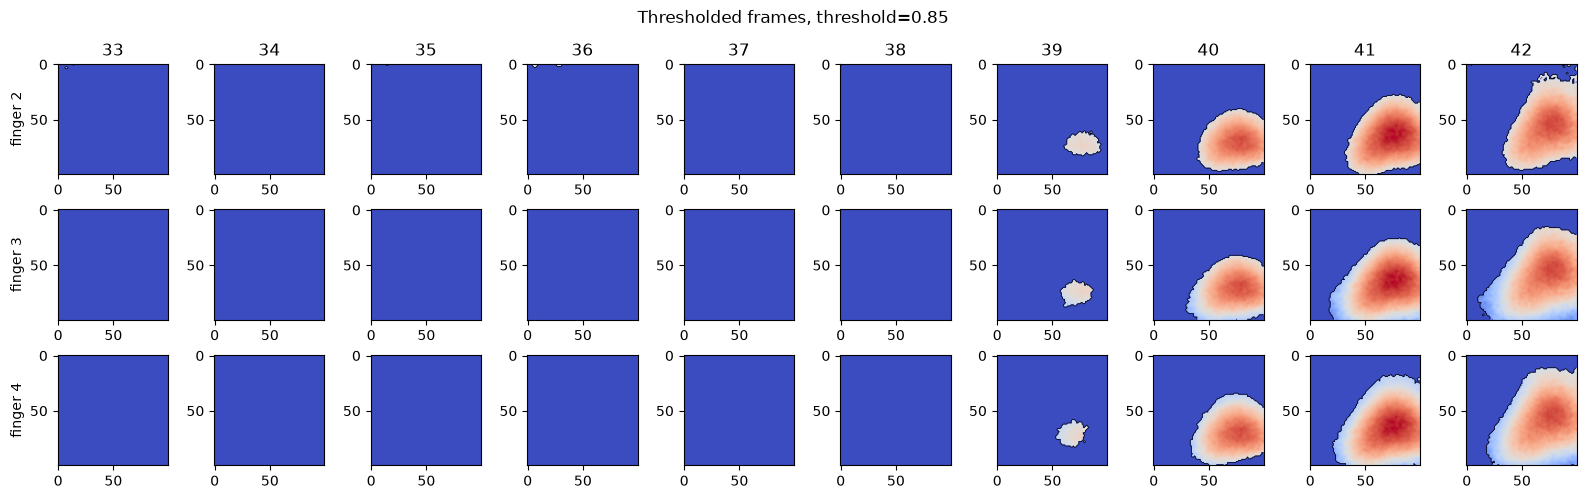

In [78]:
fig, ax = plt.subplots(3, 10, figsize=(16,5))

vmin = np.min(cond1_thresh)
vmax=np.max(cond1_thresh)

level=0

for i in range(10):
    ax[0][i].imshow(cond1_thresh[:,:,33+i], vmin=vmin, vmax=vmax, cmap='coolwarm')
    ax[1][i].imshow(cond2_thresh[:,:,33+i], vmin=vmin, vmax=vmax, cmap='coolwarm')
    ax[2][i].imshow(cond3_thresh[:,:,33+i], vmin=vmin, vmax=vmax, cmap='coolwarm')

    ax[0][i].contour(cond1_thresh[:,:,33+i], levels=level, linewidths=0.5, colors='k')
    ax[1][i].contour(cond2_thresh[:,:,33+i], levels=level, linewidths=0.5, colors='k')
    ax[2][i].contour(cond3_thresh[:,:,33+i], levels=level, linewidths=0.5, colors='k')

    ax[0][i].set_title(33+i)

ax[0][0].set_ylabel('finger 2')
ax[1][0].set_ylabel('finger 3')
ax[2][0].set_ylabel('finger 4')

fig.suptitle(f'Thresholded frames, threshold={thresh}')
plt.tight_layout()

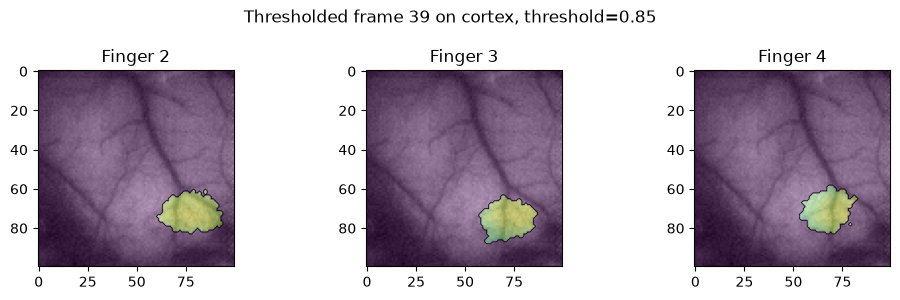

In [79]:
fig, ax = plt.subplots(1, 3, figsize=(10, 3))
frame = 39

ax[0].imshow(cond1_thresh[:,:,frame])
ax[1].imshow(cond2_thresh[:,:,frame])
ax[2].imshow(cond3_thresh[:,:,frame])

ax[0].contour(cond1_thresh[:,:,frame], levels=0, linewidths=0.5, colors='k')
ax[1].contour(cond2_thresh[:,:,frame], levels=0, linewidths=0.5, colors='k')
ax[2].contour(cond3_thresh[:,:,frame], levels=0, linewidths=0.5, colors='k')

ax[0].imshow(Cortex, alpha=0.6)
ax[1].imshow(Cortex, alpha=0.6)
ax[2].imshow(Cortex, alpha=0.6)

ax[0].set_title('Finger 2')
ax[1].set_title('Finger 3')
ax[2].set_title('Finger 4')

fig.suptitle(f'Thresholded frame {frame} on cortex, threshold={thresh}')
plt.tight_layout()

### Extracting the contour

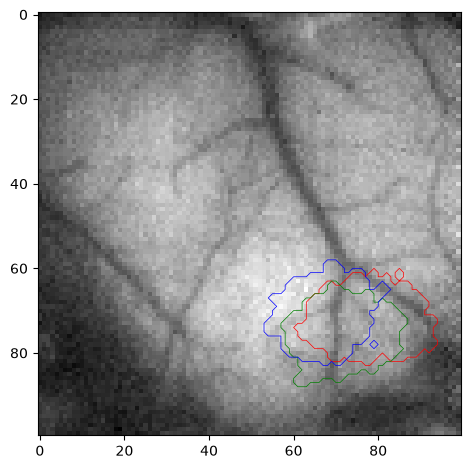

In [80]:
plt.imshow(Cortex)
plt.contour(cond1_thresh[:,:,frame], levels=0, linewidths=0.5, colors='r')
plt.contour(cond2_thresh[:,:,frame], levels=0, linewidths=0.5, colors='g')
plt.contour(cond3_thresh[:,:,frame], levels=0, linewidths=0.5, colors='b')

plt.tight_layout()

### Finding the center

In [81]:
from cv2 import moments

center1 = None
center2 = None
center3 = None

M1 = moments(cond1_thresh[:,:,39])
M2 = moments(cond2_thresh[:,:,39])
M3 = moments(cond3_thresh[:,:,39])

center1 = (int(M1["m10"] / M1["m00"]), int(M1["m01"] / M1["m00"]))
center2 = (int(M2["m10"] / M2["m00"]), int(M2["m01"] / M2["m00"]))
center3 = (int(M3["m10"] / M3["m00"]), int(M3["m01"] / M3["m00"]))

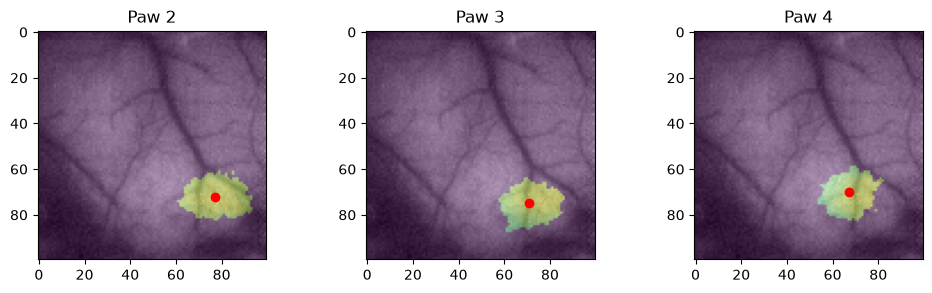

In [82]:
fig, ax = plt.subplots(1, 3, figsize=(10, 3))

ax[0].imshow(cond1_thresh[:,:,39])
ax[1].imshow(cond2_thresh[:,:,39])
ax[2].imshow(cond3_thresh[:,:,39])

ax[0].imshow(Cortex, alpha=0.6)
ax[1].imshow(Cortex, alpha=0.6)
ax[2].imshow(Cortex, alpha=0.6)

ax[0].plot(center1[0], center1[1], 'ro')
ax[1].plot(center2[0], center2[1], 'ro')
ax[2].plot(center3[0], center3[1], 'ro')

ax[0].set_title('Paw 2')
ax[1].set_title('Paw 3')
ax[2].set_title('Paw 4')

plt.tight_layout()

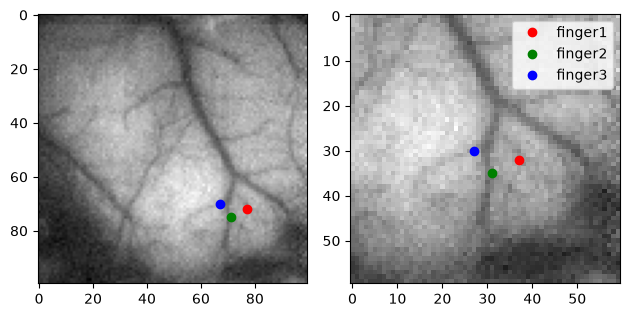

In [83]:
## Zoomed in all together

fig, (ax1, ax2) = plt.subplots(1, 2)

ax1.imshow(Cortex)
ax1.plot(center1[0], center1[1], 'ro', label='finger1')
ax1.plot(center2[0], center2[1], 'go', label='finger2')
ax1.plot(center3[0], center3[1], 'bo', label='finger3')

ax2.imshow(Cortex[40:, 40:])
ax2.plot(center1[0]-40, center1[1]-40, 'ro', label='finger1')
ax2.plot(center2[0]-40, center2[1]-40, 'go', label='finger2')
ax2.plot(center3[0]-40, center3[1]-40, 'bo', label='finger3')

plt.legend()
plt.tight_layout()

### One script to extract contours and center

In [ ]:
thresh = 0.5
level = 0